# Clustering Modelling

This notebook extends the exploratory analysis by grouping Italian
municipalities according to their road accident characteristics.

The analysis includes:

- municipality-level feature preparation
- feature transformation and scaling
- K-Means clustering
- cluster evaluation
- cluster interpretation
- identification of municipalities for further road-safety assessment

In [40]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score
)



In [41]:
cleaned_path = Path(
    "data/cleaned/istat_traffic_2020_2024_cleaned.csv"
)

df = pd.read_csv(
    cleaned_path,
    keep_default_na=False,
    na_values=[""]
)

df.shape

(39507, 13)

## 1. Municipality-Level Feature Preparation

The annual road accident data is aggregated to municipality level to create
a single analytical dataset for clustering.

The features represent different dimensions of road safety:

- average annual accident volume
- accidents per 100,000 residents
- accidents per square kilometre
- mortality index for cluster interpretation

In [42]:
# Municipality-Level Data Aggregation for Clustering

municipality_features = (
    df.groupby(["REF_AREA", "municipality"])
      .agg(
          region_code=("region_code", "first"),
          province_code=("province_code", "first"),
          province_abbr=("province_abbr", "first"),
          years_observed=("TIME_PERIOD", "nunique"),
          total_accidents=("accidents", "sum"),
          total_injured=("injured", "sum"),
          total_killed=("killed", "sum"),
          population_years=("population", "sum"),
          avg_population=("population", "mean"),
          avg_area_km2=("area_km2", "mean")
      )
      .reset_index()
)

In [43]:
# indicators:

municipality_features["avg_annual_accidents"] = (
    municipality_features["total_accidents"]
    / municipality_features["years_observed"]
)

municipality_features["accidents_per_100k"] = (
    municipality_features["total_accidents"]
    / municipality_features["population_years"]
    * 100_000
)

municipality_features["accidents_per_km2"] = (
    municipality_features["avg_annual_accidents"]
    / municipality_features["avg_area_km2"]
)

municipality_features["mortality_index"] = (
    municipality_features["total_killed"]
    / municipality_features["total_accidents"]
    * 100
)

In [44]:
municipality_features.shape

(7919, 16)

In [45]:
municipality_features.head()

,REF_AREA,municipality,region_code,province_code,province_abbr,years_observed,total_accidents,total_injured,total_killed,population_years,avg_population,avg_area_km2,avg_annual_accidents,accidents_per_100k,accidents_per_km2,mortality_index
0,1001,Agliè,1,201,TO,5,14,22,1,12856,2571.2,13.14628,2.8,108.898569,0.212988,7.142857
1,1002,Airasca,1,201,TO,5,30,47,1,18343,3668.6,15.73930,6.0,163.550128,0.381211,3.333333
2,1003,Ala di Stura,1,201,TO,5,2,3,0,2325,465.0,46.33158,0.4,86.021505,0.008633,0.000000
3,1004,Albiano d'Ivrea,1,201,TO,5,15,22,0,8144,1628.8,11.73804,3.0,184.184676,0.255579,0.000000
4,1006,Almese,1,201,TO,5,21,26,1,31590,6318.0,17.87440,4.2,66.476733,0.234973,4.761905


In [46]:
municipality_features[
    [
        "years_observed",
        "avg_annual_accidents",
        "accidents_per_100k",
        "accidents_per_km2",
        "mortality_index"
    ]
].isna().sum()

years_observed            0
avg_annual_accidents      0
accidents_per_100k        0
accidents_per_km2         0
mortality_index         476
dtype: int64

In [47]:
# confirm that everything is 0

print(
    "Municipalities with zero accidents:",
    (municipality_features["total_accidents"] == 0).sum()
)

print(
    "Missing mortality index:",
    municipality_features["mortality_index"].isna().sum()
)

Municipalities with zero accidents: 476
Missing mortality index: 476


## 2. Prepare Features for Clustering

Three road-safety indicators are selected for clustering:

- average annual accident volume
- accidents per 100,000 residents
- accidents per square kilometre

Because the variables are strongly right-skewed and contain extreme values,
a logarithmic transformation is applied first.

The transformed variables are then normalised using MinMaxScaler so that
they are placed on a comparable 0–1 scale before applying K-Means.

In [48]:
cluster_features = [
    "avg_annual_accidents",
    "accidents_per_100k",
    "accidents_per_km2"
]

X = municipality_features[cluster_features].copy()

X.describe()

,avg_annual_accidents,accidents_per_100k,accidents_per_km2
count,7919.000000,7919.000000,7919.000000
mean,19.605592,167.605783,0.573685
std,178.313969,140.262672,1.481044
min,0.000000,0.000000,0.000000
25%,1.000000,76.876799,0.038737
50%,3.200000,142.755175,0.141038
75%,10.400000,222.846605,0.479867
max,11856.000000,2654.867257,39.226307


In [49]:
X_log = np.log1p(X)

scaler = MinMaxScaler()

X_scaled = pd.DataFrame(
    scaler.fit_transform(X_log),
    columns=X.columns,
    index=X.index
)

X_scaled.describe()

,avg_annual_accidents,accidents_per_100k,accidents_per_km2
count,7919.000000,7919.000000,7919.000000
mean,0.178539,0.588270,0.083508
std,0.136805,0.175120,0.117932
min,0.000000,0.000000,0.000000
25%,0.073891,0.552364,0.010287
50%,0.152983,0.630109,0.035712
75%,0.259428,0.686276,0.106090
max,1.000000,1.000000,1.000000


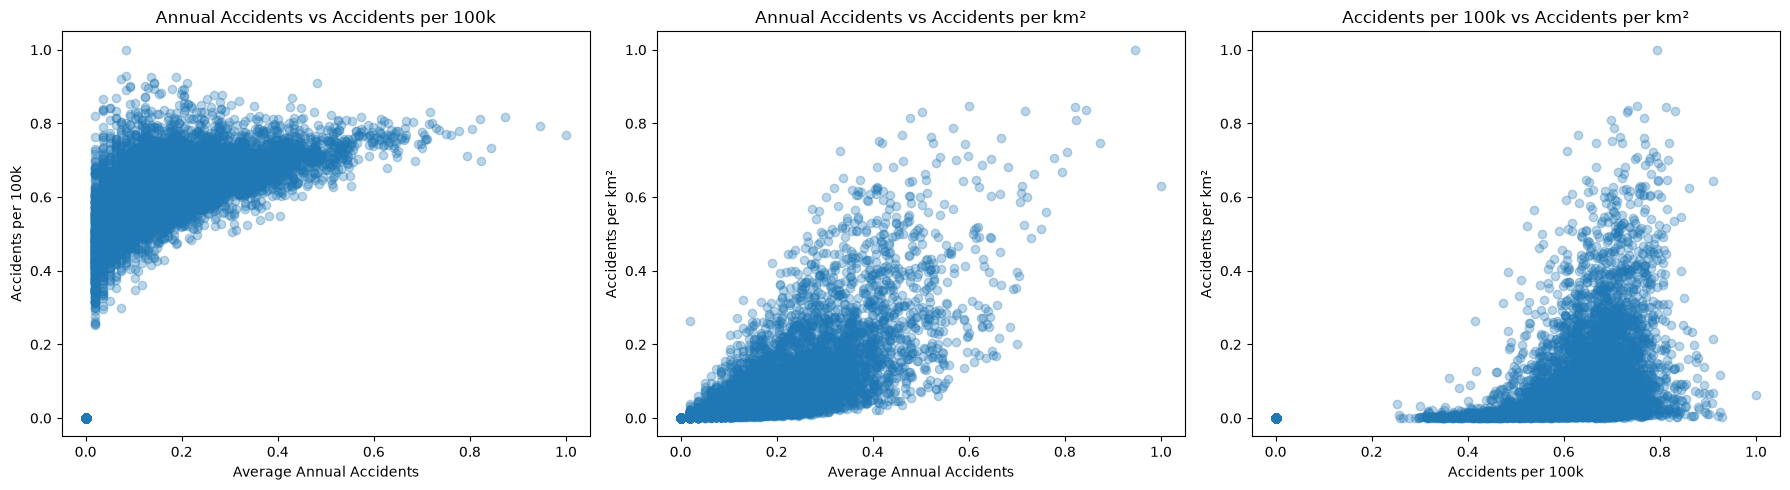

In [50]:
# Exploring Relationships Between Scaled Features

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(
    X_scaled["avg_annual_accidents"],
    X_scaled["accidents_per_100k"],
    alpha=0.3
)
axes[0].set_title("Annual Accidents vs Accidents per 100k")
axes[0].set_xlabel("Average Annual Accidents")
axes[0].set_ylabel("Accidents per 100k")

axes[1].scatter(
    X_scaled["avg_annual_accidents"],
    X_scaled["accidents_per_km2"],
    alpha=0.3
)
axes[1].set_title("Annual Accidents vs Accidents per km²")
axes[1].set_xlabel("Average Annual Accidents")
axes[1].set_ylabel("Accidents per km²")

axes[2].scatter(
    X_scaled["accidents_per_100k"],
    X_scaled["accidents_per_km2"],
    alpha=0.3
)
axes[2].set_title("Accidents per 100k vs Accidents per km²")
axes[2].set_xlabel("Accidents per 100k")
axes[2].set_ylabel("Accidents per km²")

plt.tight_layout()
plt.show()

## 3. Clustering Evaluation

Different feature combinations are tested using K-Means.

For each combination, several values of K are evaluated using:

- Within-Cluster Sum of Squares (WCSS)
- Silhouette Score
- Calinski-Harabasz Index

In [51]:
pair_1 = X_scaled[
    [
        "avg_annual_accidents",
        "accidents_per_100k"
    ]
].copy()

In [52]:
# Evaluating K-Means with Different Numbers of Clusters

k_values = range(2, 9)

wcss_1 = []
silhouette_1 = []
calinski_1 = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(pair_1)

    wcss_1.append(model.inertia_)
    silhouette_1.append(
        silhouette_score(pair_1, labels)
    )
    calinski_1.append(
        calinski_harabasz_score(pair_1, labels)
    )

In [53]:
# Comparison of K-Means Evaluation Metrics

evaluation_1 = pd.DataFrame({
    "k": list(k_values),
    "wcss": wcss_1,
    "silhouette_score": silhouette_1,
    "calinski_harabasz": calinski_1
})

evaluation_1.round(3)

,k,wcss,silhouette_score,calinski_harabasz
0,2,197.845,0.691,7729.695
1,3,95.142,0.483,12308.403
2,4,60.723,0.438,14350.951
3,5,45.839,0.411,14898.428
4,6,36.887,0.404,15193.772
5,7,30.528,0.397,15571.795
6,8,26.450,0.391,15577.144


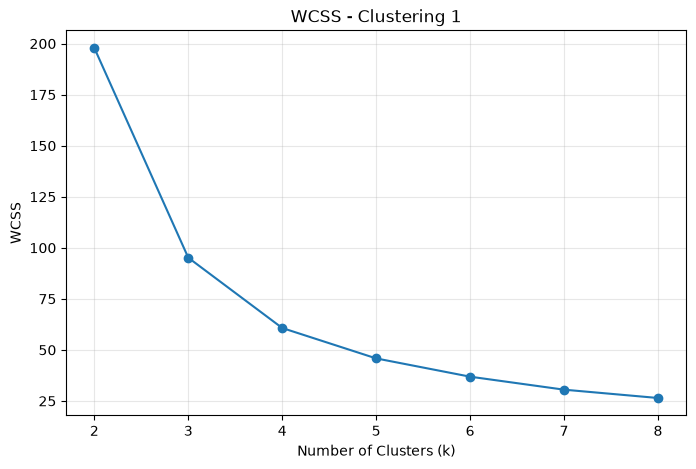

In [54]:
# Elbow Method — Selecting the Number of Clusters

plt.figure(figsize=(8, 5))

plt.plot(
    evaluation_1["k"],
    evaluation_1["wcss"],
    marker="o"
)

plt.title("WCSS - Clustering 1")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")
plt.xticks(evaluation_1["k"])
plt.grid(alpha=0.3)

plt.show()

In [55]:
# K-Means Clustering — Model Fitting and Cluster Assignment

kmeans1 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

kmeans1_result = kmeans1.fit_predict(pair_1)

municipality_features["cluster_1"] = kmeans1_result

centroids_1 = kmeans1.cluster_centers_

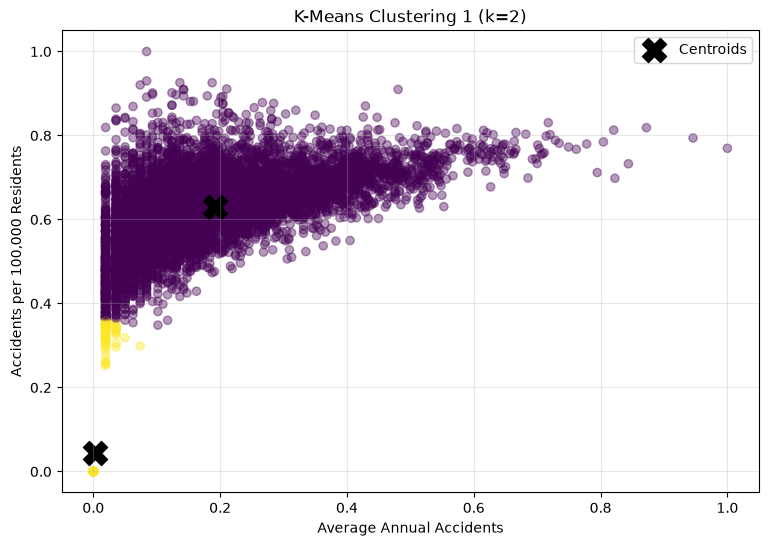

In [56]:
plt.figure(figsize=(9, 6))

plt.scatter(
    pair_1["avg_annual_accidents"],
    pair_1["accidents_per_100k"],
    c=kmeans1_result,
    cmap="viridis",
    alpha=0.4,
    marker="o"
)

plt.scatter(
    centroids_1[:, 0],
    centroids_1[:, 1],
    marker="X",
    color="black",
    s=300,
    label="Centroids"
)

plt.title("K-Means Clustering 1 (k=2)")
plt.xlabel("Average Annual Accidents")
plt.ylabel("Accidents per 100,000 Residents")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

The first clustering uses average annual accidents and accidents per
100,000 residents.

A two-cluster solution was selected as the candidate for this feature
combination because it achieved the highest Silhouette Score among the
tested values of K.

The result will later be compared with alternative feature combinations
using the same evaluation metrics.

In [57]:
# Clustering Experiment 2 — Accident Volume and Density

pair_2 = X_scaled[
    [
        "avg_annual_accidents",
        "accidents_per_km2"
    ]
].copy()

In [58]:
k_values = range(2, 9)

wcss_2 = []
silhouette_2 = []
calinski_2 = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(pair_2)

    wcss_2.append(model.inertia_)
    silhouette_2.append(
        silhouette_score(pair_2, labels)
    )
    calinski_2.append(
        calinski_harabasz_score(pair_2, labels)
    )

evaluation_2 = pd.DataFrame({
    "k": list(k_values),
    "wcss": wcss_2,
    "silhouette_score": silhouette_2,
    "calinski_harabasz": calinski_2
})

evaluation_2.round(3)

,k,wcss,silhouette_score,calinski_harabasz
0,2,110.678,0.580,10560.649
1,3,67.006,0.511,11300.566
2,4,48.943,0.469,11286.352
3,5,40.277,0.437,10710.511
4,6,32.953,0.452,10822.996
5,7,28.553,0.444,10611.051
6,8,24.561,0.423,10756.024


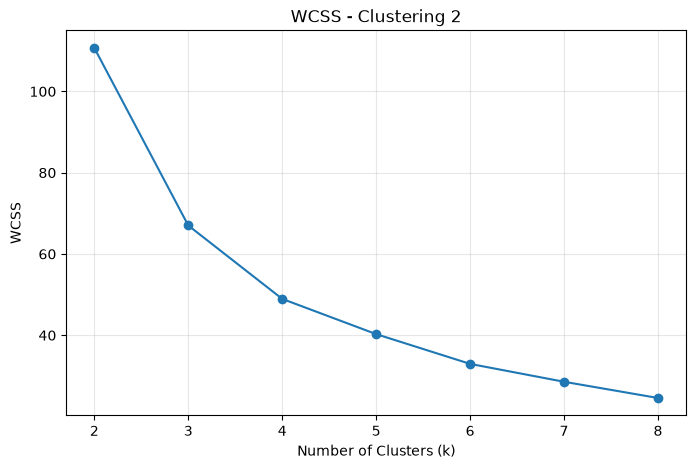

In [59]:
# Elbow Method — Accident Volume and Density

plt.figure(figsize=(8, 5))

plt.plot(
    evaluation_2["k"],
    evaluation_2["wcss"],
    marker="o"
)

plt.title("WCSS - Clustering 2")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")
plt.xticks(evaluation_2["k"])
plt.grid(alpha=0.3)

plt.show()

In [60]:
# K-Means Model — Second Feature Combination (K = 2)

kmeans2_k2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

labels_k2 = kmeans2_k2.fit_predict(pair_2)

centroids_k2 = kmeans2_k2.cluster_centers_

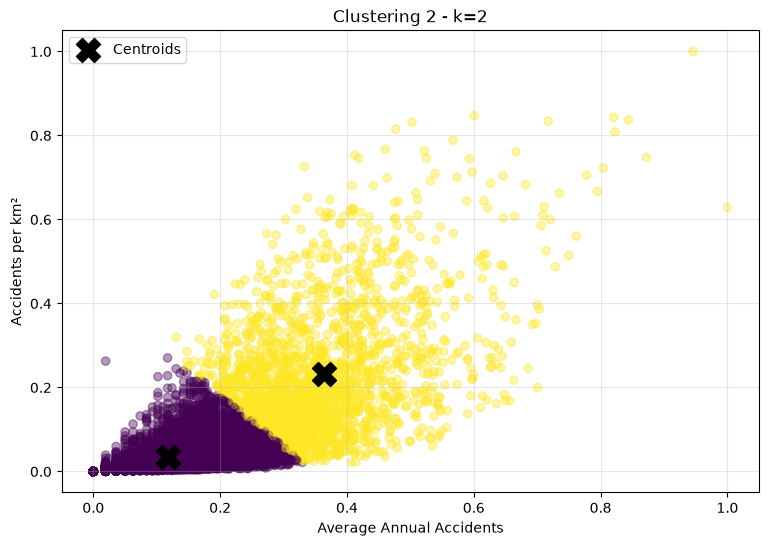

In [61]:
plt.figure(figsize=(9, 6))

plt.scatter(
    pair_2["avg_annual_accidents"],
    pair_2["accidents_per_km2"],
    c=labels_k2,
    cmap="viridis",
    alpha=0.4
)

plt.scatter(
    centroids_k2[:, 0],
    centroids_k2[:, 1],
    marker="X",
    color="black",
    s=300,
    label="Centroids"
)

plt.title("Clustering 2 - k=2")
plt.xlabel("Average Annual Accidents")
plt.ylabel("Accidents per km²")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [62]:
# K-Means Model — Second Feature Combination (K = 3)

kmeans2_k3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

labels_k3 = kmeans2_k3.fit_predict(pair_2)

centroids_k3 = kmeans2_k3.cluster_centers_

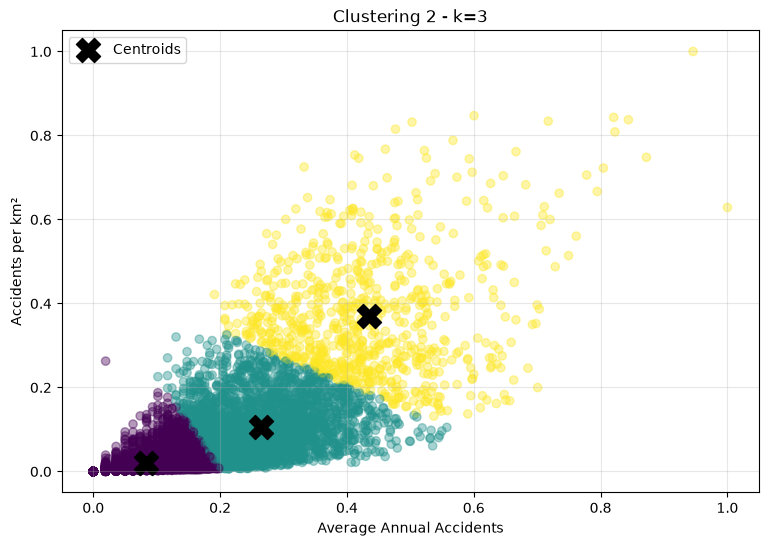

In [63]:
plt.figure(figsize=(9, 6))

plt.scatter(
    pair_2["avg_annual_accidents"],
    pair_2["accidents_per_km2"],
    c=labels_k3,
    cmap="viridis",
    alpha=0.4
)

plt.scatter(
    centroids_k3[:, 0],
    centroids_k3[:, 1],
    marker="X",
    color="black",
    s=300,
    label="Centroids"
)

plt.title("Clustering 2 - k=3")
plt.xlabel("Average Annual Accidents")
plt.ylabel("Accidents per km²")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

The second clustering uses average annual accidents and accidents per
square kilometre.

Both two- and three-cluster solutions were evaluated.

Although K = 2 achieved a higher Silhouette Score, K = 3 produced a higher
Calinski-Harabasz score and provided a more informative visual separation
between municipalities with low, medium and high accident activity and density.

For this feature combination, K = 3 is therefore retained as the candidate
solution.

In [64]:
# Clustering Experiment 3 — Population-Adjusted Rate and Accident Density

pair_3 = X_scaled[
    [
        "accidents_per_100k",
        "accidents_per_km2"
    ]
].copy()

In [65]:
k_values = range(2, 9)

wcss_3 = []
silhouette_3 = []
calinski_3 = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(pair_3)

    wcss_3.append(model.inertia_)

    silhouette_3.append(
        silhouette_score(pair_3, labels)
    )

    calinski_3.append(
        calinski_harabasz_score(pair_3, labels)
    )

In [66]:
evaluation_3 = pd.DataFrame({
    "k": list(k_values),
    "wcss": wcss_3,
    "silhouette_score": silhouette_3,
    "calinski_harabasz": calinski_3
})

evaluation_3.round(3)

,k,wcss,silhouette_score,calinski_harabasz
0,2,173.452,0.731,8192.663
1,3,94.518,0.568,10822.032
2,4,56.476,0.466,13849.758
3,5,40.898,0.467,15095.883
4,6,31.308,0.436,16258.456
5,7,26.658,0.431,16140.547
6,8,22.682,0.410,16456.201


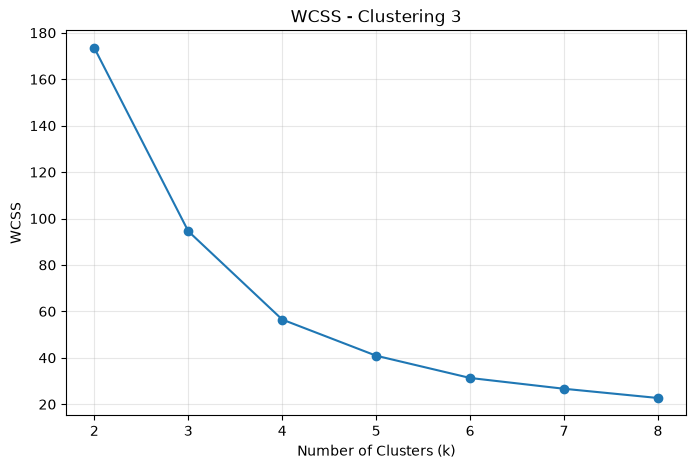

In [67]:
# Elbow Method — Population-Adjusted Accident Rate and Density

plt.figure(figsize=(8, 5))

plt.plot(
    evaluation_3["k"],
    evaluation_3["wcss"],
    marker="o"
)

plt.title("WCSS - Clustering 3")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")
plt.xticks(evaluation_3["k"])
plt.grid(alpha=0.3)

plt.show()

In [68]:
# Clustering 3 with k = 2

kmeans3_k2 = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

labels3_k2 = kmeans3_k2.fit_predict(pair_3)

centroids3_k2 = kmeans3_k2.cluster_centers_

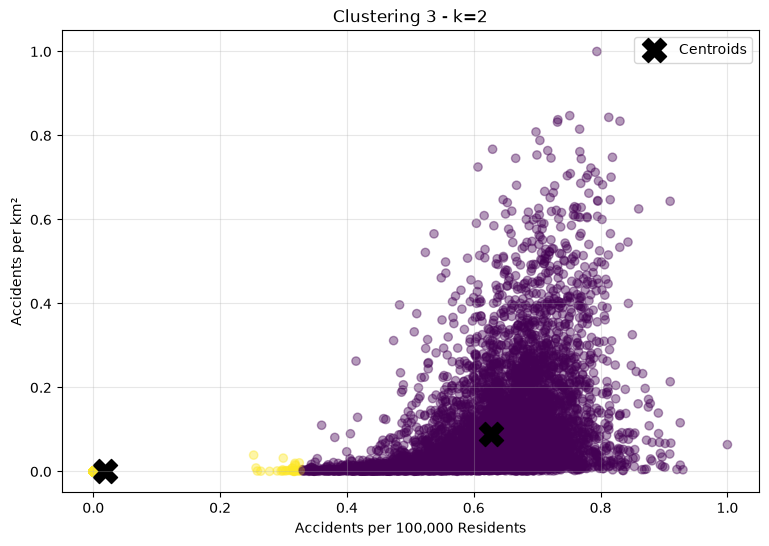

In [69]:
plt.figure(figsize=(9, 6))

plt.scatter(
    pair_3["accidents_per_100k"],
    pair_3["accidents_per_km2"],
    c=labels3_k2,
    cmap="viridis",
    alpha=0.4
)

plt.scatter(
    centroids3_k2[:, 0],
    centroids3_k2[:, 1],
    marker="X",
    color="black",
    s=300,
    label="Centroids"
)

plt.title("Clustering 3 - k=2")
plt.xlabel("Accidents per 100,000 Residents")
plt.ylabel("Accidents per km²")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [70]:
# Clustering 3 with k = 3

kmeans3_k3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

labels3_k3 = kmeans3_k3.fit_predict(pair_3)

centroids3_k3 = kmeans3_k3.cluster_centers_

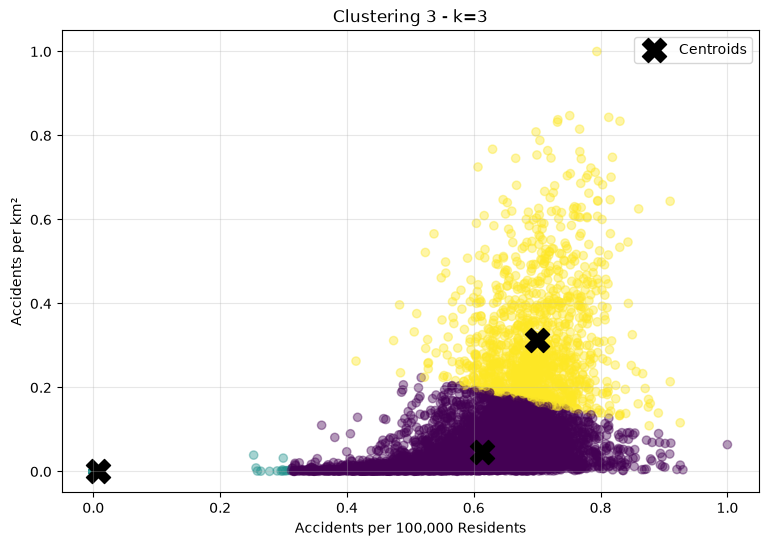

In [71]:
plt.figure(figsize=(9, 6))

plt.scatter(
    pair_3["accidents_per_100k"],
    pair_3["accidents_per_km2"],
    c=labels3_k3,
    cmap="viridis",
    alpha=0.4
)

plt.scatter(
    centroids3_k3[:, 0],
    centroids3_k3[:, 1],
    marker="X",
    color="black",
    s=300,
    label="Centroids"
)

plt.title("Clustering 3 - k=3")
plt.xlabel("Accidents per 100,000 Residents")
plt.ylabel("Accidents per km²")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 4. Clustering Comparison

The candidate clustering solutions are compared using the Silhouette Score
and Calinski-Harabasz Index.

The evaluation also considers visual separation and the business
interpretability of the resulting municipality groups.

In [72]:
clustering_comparison = pd.DataFrame({
    "clustering": [
        "Clustering 1",
        "Clustering 2",
        "Clustering 3"
    ],
    "features": [
        "Annual accidents + Accidents per 100k",
        "Annual accidents + Accidents per km²",
        "Accidents per 100k + Accidents per km²"
    ],
    "k": [
        2,
        3,
        3
    ],
    "silhouette_score": [
        evaluation_1.loc[
            evaluation_1["k"] == 2,
            "silhouette_score"
        ].iloc[0],

        evaluation_2.loc[
            evaluation_2["k"] == 3,
            "silhouette_score"
        ].iloc[0],

        evaluation_3.loc[
            evaluation_3["k"] == 3,
            "silhouette_score"
        ].iloc[0]
    ],
    "calinski_harabasz": [
        evaluation_1.loc[
            evaluation_1["k"] == 2,
            "calinski_harabasz"
        ].iloc[0],

        evaluation_2.loc[
            evaluation_2["k"] == 3,
            "calinski_harabasz"
        ].iloc[0],

        evaluation_3.loc[
            evaluation_3["k"] == 3,
            "calinski_harabasz"
        ].iloc[0]
    ]
})

clustering_comparison.round(3)

,clustering,features,k,silhouette_score,calinski_harabasz
0,Clustering 1,Annual accidents + Accidents per 100k,2,0.691,7729.695
1,Clustering 2,Annual accidents + Accidents per km²,3,0.511,11300.566
2,Clustering 3,Accidents per 100k + Accidents per km²,3,0.568,10822.032


The comparison shows that Clustering 1 achieved the highest Silhouette Score (0.691), while Clustering 2 achieved the highest Calinski-Harabasz Score (11,300.566).

Clustering 3 achieved a Silhouette Score of 0.568 and a Calinski-Harabasz Score of 10,822.032.

Although Clustering 3 did not achieve the highest scores, it uses two important indicators: accidents per 100,000 residents and accidents per km².

These indicators allow us to compare municipalities based on population and geographical area rather than only the total number of accidents.

I selected Clustering 3 with K = 3 because it provides a good balance between statistical performance and meaningful interpretation.

In [73]:
# Assign Final Cluster Labels to Municipalities

municipality_features["cluster"] = labels3_k3

In [74]:
cluster_profile = (
    municipality_features
    .groupby("cluster")
    .agg(
        municipalities=("municipality", "count"),
        median_population=("avg_population", "median"),
        median_annual_accidents=("avg_annual_accidents", "median"),
        median_accidents_per_100k=("accidents_per_100k", "median"),
        median_accidents_per_km2=("accidents_per_km2", "median"),
        median_mortality_index=("mortality_index", "median")
    )
)

cluster_profile.round(2)

,municipalities,median_population,median_annual_accidents,median_accidents_per_100k,median_accidents_per_km2,median_mortality_index
cluster,,,,,,
0,6225,2085.2,2.6,135.08,0.11,0.00
1,489,373.6,0.0,0.00,0.00,0.00
2,1205,12422.0,27.8,246.71,1.67,1.52


Cluster Interpretation and Naming

After selecting Clustering 3 with K = 3, I analysed the characteristics of each cluster using the original municipality-level data.

The results identified three different profiles:

Cluster 0 (6,225 municipalities): Relatively low accident activity and accident density.
Cluster 1 (489 municipalities): Minimal or no recorded accident activity, with median accident indicators equal to zero.
Cluster 2 (1,205 municipalities): Higher accident rates and accident density compared to the other groups.

Based on these findings, I assigned descriptive names to each cluster to make the results easier to understand and communicate.

In [75]:
# Assigning Meaningful Names to Clusters

cluster_names = {
    0: "Low Accident Activity",
    1: "Minimal / No Accident Activity",
    2: "Higher Accident Activity and Density"
}

municipality_features["cluster_name"] = (
    municipality_features["cluster"]
    .map(cluster_names)
)

In [76]:
municipality_features[
    [
        "municipality",
        "cluster",
        "cluster_name"
    ]
].head(10)

,municipality,cluster,cluster_name
0,Agliè,0,Low Accident Activity
1,Airasca,0,Low Accident Activity
2,Ala di Stura,0,Low Accident Activity
3,Albiano d'Ivrea,0,Low Accident Activity
4,Almese,0,Low Accident Activity
5,Alpette,0,Low Accident Activity
6,Alpignano,2,Higher Accident Activity and Density
7,Andezeno,0,Low Accident Activity
8,Andrate,0,Low Accident Activity
9,Angrogna,1,Minimal / No Accident Activity


## 5. Clustering Conclusions and Business Implications

The clustering analysis identified three distinct municipality profiles:

- **Minimal / No Accident Activity**(489 municipalities): municipalities with little or no
  recorded accident activity.
- **Low Accident Activity**(6,225 municipalities): municipalities with relatively low
  population-adjusted accident rates and accident density.
- **Higher Accident Activity and Density**(1,205 municipalities): municipalities with substantially
  higher accident rates per 100,000 residents and higher accident density
  per square kilometre.

From a business perspective, the **Higher Accident Activity and Density**
cluster represents the main group for further investigation when prioritising
road-safety investment.

However, cluster membership should not be used as the only basis for funding
decisions. Municipalities within this group should be further evaluated using
accident severity, mortality, recent trends and regression model results.

The clustering therefore provides a first prioritisation step, helping the
business narrow thousands of municipalities into groups with different
road-safety profiles.

### Priority municipalities by population-adjusted accident rate

Within the Higher Accident Activity and Density cluster, municipalities with
an average population of at least 5,000 residents are examined separately.

This exploratory threshold reduces the influence of very small population
denominators.

The municipalities are ranked primarily by accidents per 100,000 residents,
with accident density used as a secondary sorting criterion.

In [77]:
priority_municipalities = (
    municipality_features[
        (municipality_features["cluster_name"]
        == "Higher Accident Activity and Density")
        &
        (municipality_features["avg_population"] >= 5000)
    ]
    .sort_values(
        ["accidents_per_100k", "accidents_per_km2"],
        ascending=False
    )
)

priority_municipalities[
    [
        "REF_AREA",
        "municipality",
        "province_abbr",
        "avg_population",
        "avg_annual_accidents",
        "accidents_per_100k",
        "accidents_per_km2",
        "mortality_index"
    ]
].head(20)

,REF_AREA,municipality,province_abbr,avg_population,avg_annual_accidents,accidents_per_100k,accidents_per_km2,mortality_index
4188,46013,Forte dei Marmi,LU,6896.4,89.8,1302.128647,9.774894,0.222717
3852,37005,Bentivoglio,BO,5762.6,55.0,954.430292,1.076210,2.545455
3551,30049,Lignano Sabbiadoro,UD,6869.2,53.2,774.471554,3.385999,1.127820
1300,10054,Santa Margherita Ligure,GE,8516.0,65.6,770.314702,6.525649,1.219512
1867,16024,Bergamo,BG,119964.8,836.4,697.204513,20.793194,0.549976
1274,10028,Lavagna,GE,12336.8,85.8,695.480189,6.186200,0.466200
4233,48005,Calenzano,FI,18128.0,119.2,657.546337,1.551038,2.516779
1271,10025,Genova,GE,563061.2,3575.0,634.922101,14.859868,0.447552
7531,99013,Riccione,RN,34572.8,215.8,624.190115,12.316845,0.370714
1716,15011,Assago,MI,9236.6,57.2,619.275491,7.103702,0.349650


The clustering identifies municipalities with comparatively high
population-adjusted accident rates and accident density.

Within the Higher Accident Activity and Density cluster, municipalities with
an average population of at least 5,000 residents are used to create a more
focused shortlist for further assessment.

This shortlist is ranked primarily by accidents per 100,000 residents, with
accident density used as a secondary criterion.

The shortlist should not be interpreted as a final funding decision.
Accident volume, severity, recent trends and predictive model results should
also be considered.

In [78]:
from pathlib import Path

powerbi_path = Path("data/powerbi")
powerbi_path.mkdir(parents=True, exist_ok=True)

cluster_output = municipality_features[
    [
        "REF_AREA",
        "municipality",
        "region_code",
        "province_code",
        "province_abbr",
        "years_observed",
        "total_accidents",
        "total_injured",
        "total_killed",
        "avg_population",
        "avg_area_km2",
        "avg_annual_accidents",
        "accidents_per_100k",
        "accidents_per_km2",
        "mortality_index",
        "cluster",
        "cluster_name"
    ]
].copy()

cluster_output.to_csv(
    powerbi_path / "municipality_clustering_2020_2024.csv",
    index=False,
    encoding="utf-8-sig"
)

cluster_output.shape

(7919, 17)

In [79]:
total_cluster_2 = (municipality_features["cluster"] == 2).sum()

filtered_cluster_2 = (
    (municipality_features["cluster"] == 2)
    &
    (municipality_features["avg_population"] >= 5000)
).sum()

print("Total Cluster 2:", total_cluster_2)
print("Population >= 5000:", filtered_cluster_2)
print("Difference:", total_cluster_2 - filtered_cluster_2)

Total Cluster 2: 1205
Population >= 5000: 995
Difference: 210


Cluster Validation — Power BI Consistency Check

The final clustering model identified 1,205 municipalities in the Higher Accident Activity and Density cluster.

All 7,919 municipality observations were exported to Power BI without applying a population filter.

In Power BI, a DAX measure called Priority Municipalities counts municipalities belonging to the Higher Accident Activity and Density cluster with an average population of at least 5,000 residents.

This measure returns 995 municipalities, excluding 210 smaller municipalities from the priority selection.

A separate validation in Python confirmed the same result.

The population filter is applied within the DAX measure, not during the CSV export.